# 10 · SVM for pump diagnostics

The practical part of lab 10. On operating records of centrifugal pumps you compare a linear model with kernel SVMs,
**tune C and γ on your own** with cross-validation, choose the decision threshold by the cost of errors and test the result once.
Then you try two other SVM tasks from the lecture: the one-class SVM trained without labelled faults and regression of the pump curve
with the ε-tube, including extrapolation. You have seen every setting you tune here in the educational part `svm-visual-en.ipynb`.

Short runnable examples use small illustrative data and variables prefixed with `demo_`. Run them in order;
they show the syntax of the whole workflow. Write your solution in the empty code cells below the tasks.
The test set is opened only in step 7. When you are done, run `Restart Kernel and Run All` to check that your solution runs in order.

## Environment setup and data loading

1. Open the notebook in Jupyter (the README describes the packages) or in Google Colab.
2. Run the example below. It imports every tool you will need and prepares small illustrative `demo_` data.
3. The prepared cell below it loads the data into the table `raw` and sets `SEED = 42`. It uses the local file `data/pumps.csv`
   when the notebook runs in the lab folder or the repository root; otherwise it creates the same table with the same generator
   (the code of `prepare_data.py`), so no download is needed.

### Example: imports and illustrative data

In [1]:
from IPython.display import display                          # Display tables.
import matplotlib.pyplot as plt                              # Plots.
import numpy as np                                           # Numerical operations.
import pandas as pd                                          # Data and result tables.
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV  # Splitting, cross-validation and grid search.
from sklearn.pipeline import Pipeline                        # Chain scaling and a model.
from sklearn.preprocessing import StandardScaler             # Standardisation.
from sklearn.linear_model import LogisticRegression          # Logistic neuron from lecture 09.
from sklearn.svm import SVC, SVR, OneClassSVM                # SVM for classification, regression and one class.
from sklearn.metrics import confusion_matrix, roc_auc_score, mean_absolute_error  # Confusion matrix, ROC AUC, MAE.

demo_rng = np.random.default_rng(7)                          # Illustrative data, not the assignment data.
demo_X = pd.DataFrame({"a": demo_rng.normal(0, 1, 400), "b": demo_rng.normal(0, 10, 400)})  # Two features on different scales.
demo_y = ((demo_X["a"] ** 2 + (demo_X["b"] / 10) ** 2) > 1.6).astype(int)  # Class 1 outside a circle: no line separates it.
demo_X_dev, demo_X_test, demo_y_dev, demo_y_test = train_test_split(demo_X, demo_y, test_size=0.25, stratify=demo_y, random_state=7)  # A quarter for the test.
demo_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)  # Five folds with the same share of classes.
print(len(demo_X_dev), len(demo_X_test), "class 1 share:", round(demo_y.mean(), 3))  # Sizes and share.

300 100 class 1 share: 0.412


**Prepared code:**

In [2]:
from pathlib import Path                                     # Paths to a local copy of the data.
SEED = 42                                                    # The same random split for everyone.


def make_pumps(seed=20261124, n=900):
    # The generator from prepare_data.py: the same table without a download.
    rng = np.random.default_rng(seed)
    flow = rng.uniform(20, 80, n)
    deviation = rng.normal(0, 0.45, n)
    pressure = 6.0 - 0.0006 * flow ** 2 + deviation
    bearing_temp = rng.normal(60, 6, n)
    current = 18 + 0.12 * flow + 0.4 * pressure + rng.normal(0, 0.6, n)
    vibration = np.exp(rng.normal(-0.5, 0.35, n))
    ambient_temp = rng.normal(22, 4, n)
    risk = (deviation / 0.45) ** 2 + ((bearing_temp - 60) / 6) ** 2 + rng.normal(0, 0.6, n)
    return pd.DataFrame({"record_id": [f"R{i:03d}" for i in range(1, n + 1)], "flow": flow.round(1), "pressure": pressure.round(3),
                         "bearing_temp": bearing_temp.round(1), "current": current.round(2), "vibration": vibration.round(3),
                         "ambient_temp": ambient_temp.round(1), "fault": (risk > 3.2).astype(int)})


local = [Path("data/pumps.csv"), Path("10-SVM/data/pumps.csv")]  # The lab folder or the repository root.
found = [path for path in local if path.exists()]           # Local copies that exist.
raw = pd.read_csv(found[0]) if found else make_pumps()       # Without a local copy (e.g. Google Colab) generate the same data.
print("data source:", found[0] if found else "make_pumps()")  # File or generator.
display(raw.head())                                          # The first five rows.

data source: data\pumps.csv


,record_id,flow,pressure,bearing_temp,current,vibration,ambient_temp,fault
0,R001,77.6,2.490,62.5,28.01,0.888,17.7,0
1,R002,77.8,1.723,66.2,27.78,0.736,19.2,0
2,R003,27.5,6.634,49.1,23.00,0.974,23.7,1
3,R004,40.6,4.673,62.4,23.82,0.678,18.6,0
4,R005,54.5,4.243,65.4,26.82,1.279,24.5,0


## Problem and data

Each row is one **operating record of a centrifugal pump** (all pumps are of the same type) with the result of an inspection `fault`
(1 = fault found). The data are synthetic; their description is in `data/README.md`.

| Column | Meaning | Typical value |
|---|---|---|
| `flow` | flow rate, the operating point | 20 to 80 m³/h |
| `pressure` | discharge pressure | 2 to 6 bar |
| `bearing_temp` | bearing temperature | 60 °C |
| `current` | motor current | 28 A |
| `vibration` | vibration velocity | 0.6 mm/s |
| `ambient_temp` | ambient temperature | 22 °C |

**Goal:** flag records that should be inspected. **Costs:** a missed fault (FN) costs **10** units (an unplanned stop),
a needless inspection (FP) costs **1** unit. The quality of a decision is measured by the **total cost** 10·FN + 1·FP.
(The cost is not called C here, so as not to mix it up with the SVM parameter C.)

## 1. Inspection (prepared)

**Output:** the share of faults, a table of feature ranges and two scatter plots. Look at where the faults lie relative to the
cloud of normal records in the plot of flow and pressure.

**Prepared code:**

rows: 900 | share of faults: 0.19


,mean,std,min,max
flow,50.22,17.45,20.10,80.00
pressure,4.30,1.15,1.24,6.98
bearing_temp,60.14,5.96,41.30,78.70
current,25.69,1.78,21.71,29.58
vibration,0.64,0.23,0.16,1.82
ambient_temp,21.96,3.94,8.00,33.60


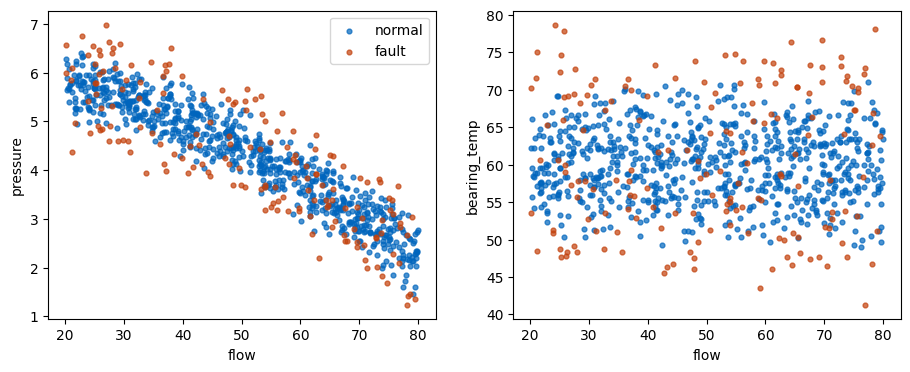

In [3]:
print("rows:", len(raw), "| share of faults:", round(raw["fault"].mean(), 3))  # Size and class share.
display(raw.drop(columns=["record_id", "fault"]).describe().T[["mean", "std", "min", "max"]].round(2))  # Ranges of the inputs.
fig, axs = plt.subplots(1, 2, figsize=(11, 4))               # Two plots side by side.
for ax, col in zip(axs, ["pressure", "bearing_temp"]):       # Pressure and bearing temperature against flow.
    for value, colour, label in ((0, "#0065BD", "normal"), (1, "#C2410C", "fault")):
        part = raw[raw["fault"] == value]
        ax.scatter(part["flow"], part[col], s=12, color=colour, label=label, alpha=0.7)
    ax.set(xlabel="flow", ylabel=col)
axs[0].legend()
plt.show()                                                   # Display the plots.

## 2. Features and a fixed split (prepared)

**Output:** `X` (six inputs) and `y` (`fault`); a development part `X_dev`, `y_dev` (675 records) and a test set `X_test`, `y_test`
(225 records) that stays closed until step 7; the folds `CV` (5-fold stratified cross-validation) used in every comparison.

**Prepared code:**

In [4]:
FEATURES = ["flow", "pressure", "bearing_temp", "current", "vibration", "ambient_temp"]  # The six inputs.
X = raw[FEATURES]                                            # Inputs; record_id is not an input.
y = raw["fault"]                                             # Target class.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)  # A quarter for the test, stratified.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # The same five folds for every model.
print(f"dev {len(y_dev)} records, {int(y_dev.sum())} faults | test {len(y_test)} records, {int(y_test.sum())} faults")

dev 675 records, 128 faults | test 225 records, 43 faults


## 3. Evaluation functions and a reference model (prepared)

**Output:** `cv_auc(model)` returns the mean ROC AUC of 5-fold cross-validation on the development data
(ROC AUC does not depend on the threshold, so it is used for tuning); `evaluate(y_true, y_pred)` returns the confusion-matrix counts,
precision, recall and the total cost. The reference is the logistic neuron from lab 09 with scaling.

**Prepared code:**

In [5]:
def cv_auc(model, X_=None, y_=None, cv=None):
    # Mean ROC AUC over the folds; by default on the development data with CV.
    X_ = X_dev if X_ is None else X_
    y_ = y_dev if y_ is None else y_
    return cross_val_score(model, X_, y_, cv=CV if cv is None else cv, scoring="roc_auc").mean()


def evaluate(y_true, y_pred):
    # Counts, two metrics and the cost 10·FN + 1·FP.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "precision": tp / max(tp + fp, 1),
            "recall": tp / max(tp + fn, 1), "cost": 10 * fn + fp}


reference = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression())])  # Scaling, then a logistic neuron.
print("logistic neuron, CV ROC AUC:", round(cv_auc(reference), 3))  # About 0.5 = no better than chance.
print("cost of 'everything normal' on dev:", 10 * int(y_dev.sum()))  # Every fault missed.

logistic neuron, CV ROC AUC: 0.457
cost of 'everything normal' on dev: 1280


## 4. Linear model versus kernels

**Goal / output:** a table `kernel_results` with the CV ROC AUC of four models on the development data:

1. linear SVM: `Pipeline` with `scale`: `StandardScaler()` → `model`: `SVC(kernel="linear")`;
2. polynomial kernel of degree 2: `SVC(kernel="poly", degree=2, coef0=1)` after scaling;
3. RBF kernel with default settings: `SVC()` after scaling;
4. the same RBF kernel **without** scaling.

**Use:** `Pipeline`, `StandardScaler`, `SVC`, `cv_auc`, `pd.Series` or `pd.DataFrame`.

<details><summary>Hint</summary>

The kernel goes in the `kernel` argument (`"linear"`, `"poly"`, `"rbf"`; the default is `"rbf"` with `C=1` and `gamma="scale"`).
`coef0=1` adds the constant r = 1 to the polynomial kernel (γ·x·z + 1)^d, so that it contains all products up to degree d.
Collect the results in a dictionary `{name: cv_auc(model)}` and turn it into `pd.Series(...)`.

</details>

**Think about:** Why is the linear model no better than chance (look at the plot in step 1)? Why does degree 2 already help?
How much does scaling matter, and why (educational part, section 5)?

### Example: kernels on the illustrative data

In [6]:
demo_models = {                                              # Three kernels after scaling, one without.
    "linear": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="linear"))]),
    "poly 2": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="poly", degree=2, coef0=1))]),
    "RBF": Pipeline([("scale", StandardScaler()), ("model", SVC())]),
    "RBF unscaled": SVC(),
}
demo_results = pd.Series({name: cv_auc(model, demo_X_dev, demo_y_dev, demo_cv) for name, model in demo_models.items()}, name="CV ROC AUC")  # One number per model.
display(demo_results.round(3))                               # The circle needs a kernel and scaling.

linear          0.609
poly 2          0.998
RBF             0.997
RBF unscaled    0.850
Name: CV ROC AUC, dtype: float64

**Your code:**

In [7]:
models = {
    "linear SVM": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="linear"))]),
    "polynomial d = 2": Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="poly", degree=2, coef0=1))]),
    "RBF": Pipeline([("scale", StandardScaler()), ("model", SVC())]),
    "RBF unscaled": SVC(),
}
kernel_results = pd.Series({name: cv_auc(model) for name, model in models.items()}, name="CV ROC AUC")
display(kernel_results.round(3))

linear SVM          0.493
polynomial d = 2    0.858
RBF                 0.867
RBF unscaled        0.796
Name: CV ROC AUC, dtype: float64

**Solution notes (step 4).** CV ROC AUC: linear SVM 0.49, polynomial degree 2 0.86, RBF 0.87, RBF without scaling 0.80
(the logistic neuron in step 3: 0.46). A fault is a deviation from the pump curve **on either side** and an unusual bearing temperature
in either direction; such a class lies around the normal records, not on one side of them, and no hyperplane separates it.
Degree 2 adds squares and products of the features, which is enough for a curved band. Without scaling the flow (tens) dominates
the distances in the RBF kernel.

## 5. Tuning C and γ

**Goal / output:** a fitted `GridSearchCV` object `grid` for the RBF pipeline, a heatmap of its CV ROC AUC, and the final
`best_svm` (its `best_estimator_`) with the number of support vectors.

1. Pipeline `scale` → `model`: `SVC()`; grid `model__C` ∈ {0.1, 1, 10, 100}, `model__gamma` ∈ {0.01, 0.1, 1, 10};
   `cv=CV`, `scoring="roc_auc"`. Fit it on the development data.
2. Show the mean CV scores as a table C × γ (`pivot_table`) and as a heatmap.
3. If the best value lies **on the edge of the grid**, extend the grid in that direction (and around the best γ) and search again.
   Repeat while the best CV score still improves noticeably (by more than about 0.005). Store the final search in `grid`
   and its best model in `best_svm`.
4. Print the number of support vectors of `best_svm` (`best_svm[-1].n_support_`) compared with the number of training records.

**Use:** `GridSearchCV`, `.cv_results_`, `pd.DataFrame(...).pivot_table(...)`, `plt.imshow`, `.best_params_`, `.best_score_`, `.best_estimator_`.

<details><summary>Hint</summary>

Parameters of a pipeline step are named `step__parameter`, here `model__C` and `model__gamma`. The table:
`pd.DataFrame(grid.cv_results_).pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score")`.
`GridSearchCV` refits the best combination on all development data (`refit=True` by default).

</details>

**Think about:** In which direction did you extend the grid? Did both C and γ change? How does the best model relate to
the lecture slide on the joint choice of C and γ?

### Example: grid search on the illustrative data

param_model__gamma,0.1,1.0,10.0
param_model__C,,,
0.1,0.958,0.997,0.993
1.0,1.000,0.997,0.991
10.0,0.998,0.999,0.987


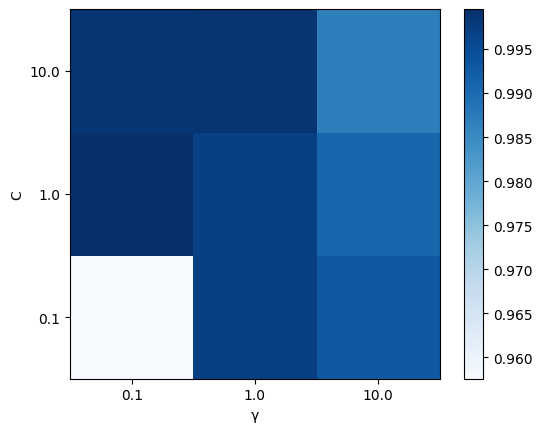

{'model__C': 1, 'model__gamma': 0.1} 1.0 support vectors: 131


In [8]:
demo_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])  # Scaling and an RBF SVM.
demo_grid = GridSearchCV(demo_pipe, {"model__C": [0.1, 1, 10], "model__gamma": [0.1, 1, 10]},  # Nine combinations.
                         cv=demo_cv, scoring="roc_auc").fit(demo_X_dev, demo_y_dev)  # Each one cross-validated.
demo_table = pd.DataFrame(demo_grid.cv_results_).pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score")  # C × γ table.
display(demo_table.round(3))
plt.imshow(demo_table.values, cmap="Blues", origin="lower")  # Heatmap; rows C, columns γ.
plt.xticks(range(3), demo_table.columns); plt.yticks(range(3), demo_table.index)
plt.xlabel("γ"); plt.ylabel("C"); plt.colorbar(); plt.show()
print(demo_grid.best_params_, round(demo_grid.best_score_, 3), "support vectors:", demo_grid.best_estimator_[-1].n_support_.sum())

**Your code:**

param_model__gamma,0.01,0.10,1.00,10.00
param_model__C,,,,
0.1,0.824,0.843,0.854,0.777
1.0,0.824,0.854,0.850,0.777
10.0,0.826,0.898,0.830,0.777
100.0,0.861,0.908,0.829,0.777


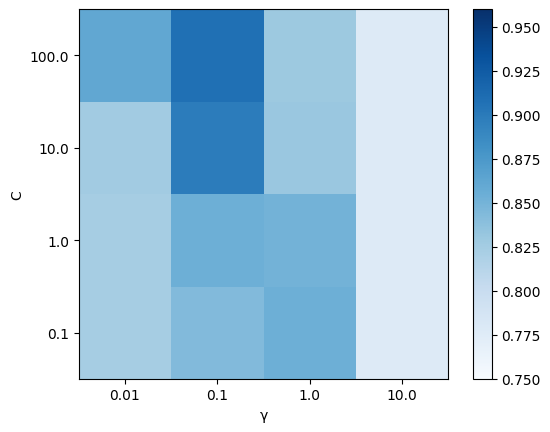

{'model__C': 100, 'model__gamma': 0.1} 0.908


param_model__gamma,0.001,0.003,0.010,0.030,0.100
param_model__C,,,,,
100,0.819,0.824,0.861,0.908,0.908
1000,0.826,0.858,0.915,0.938,0.858
10000,0.861,0.919,0.944,0.906,0.846
100000,0.916,0.950,0.933,0.859,0.846


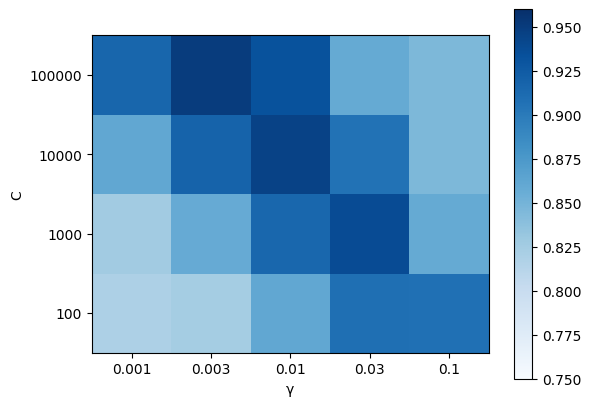

{'model__C': 100000, 'model__gamma': 0.003} 0.95


C = 10⁶: best CV ROC AUC 0.951 – plateau, no further extension
support vectors per class: [75 66] of 675


In [9]:
pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])


def show_grid(search):
    table = pd.DataFrame(search.cv_results_).pivot_table(index="param_model__C", columns="param_model__gamma", values="mean_test_score")
    display(table.round(3))
    plt.imshow(table.values, cmap="Blues", origin="lower", vmin=0.75, vmax=0.96)
    plt.xticks(range(table.shape[1]), table.columns); plt.yticks(range(table.shape[0]), table.index)
    plt.xlabel("γ"); plt.ylabel("C"); plt.colorbar(); plt.show()
    print(search.best_params_, round(search.best_score_, 3))


first = GridSearchCV(pipe, {"model__C": [0.1, 1, 10, 100], "model__gamma": [0.01, 0.1, 1, 10]}, cv=CV, scoring="roc_auc").fit(X_dev, y_dev)
show_grid(first)
# The best C = 100 is on the edge: extend C upwards and γ downwards (good cells lie on a diagonal).
grid = GridSearchCV(pipe, {"model__C": [100, 1000, 10000, 100000], "model__gamma": [0.001, 0.003, 0.01, 0.03, 0.1]}, cv=CV, scoring="roc_auc").fit(X_dev, y_dev)
show_grid(grid)
# C = 100000 is on the edge again: one more check further along the diagonal.
further = GridSearchCV(pipe, {"model__C": [1000000], "model__gamma": [0.001, 0.003]}, cv=CV, scoring="roc_auc").fit(X_dev, y_dev)
print("C = 10⁶: best CV ROC AUC", round(further.best_score_, 3), "– plateau, no further extension")
best_svm = grid.best_estimator_
print("support vectors per class:", best_svm[-1].n_support_, "of", len(X_dev))

**Solution notes (step 5).** The first grid has its best CV ROC AUC 0.908 at C = 100, γ = 0.1 – on the edge of C. Good cells lie on a diagonal
(larger C with smaller γ), so the second grid extends C upwards and γ downwards: 0.938 at C = 1000, γ = 0.03, 0.944 at C = 10⁴, γ = 0.01 and
**0.950 at C = 10⁵, γ = 0.003** – again on the edge. C = 10⁶ gives 0.950–0.951: a plateau, the search stops. Along this diagonal the RBF
boundary becomes smooth (small γ) and strict (large C); it approaches a low-degree polynomial, which matches the true shape of the classes
(a tuned polynomial kernel of degree 2 reaches about 0.94). The best model has 141 support vectors (75 + 66) of 675 records.
Training with C = 10⁵ is noticeably slower than with C = 1.

## 6. Threshold by the cost of errors

**Goal / output:** cross-validated scores `dev_scores` of the best settings on the development data, a plot of the total cost against
the threshold, the threshold `best_threshold` with the lowest cost, and a comparison with the threshold 0 (the default of `predict`).

1. `dev_scores = cross_val_predict(best_svm, X_dev, y_dev, cv=CV, method="decision_function")` – every record gets a score from a model
   that did not see it.
2. For thresholds from −2 to 1 (step 0.05) compute the cost of `(dev_scores >= threshold)`; plot it and find the minimum.
3. Print `evaluate` at the best threshold and at 0.

**Use:** `cross_val_predict`, `np.arange`, `evaluate`, `plt.plot`.

<details><summary>Hint</summary>

The SVM score is the signed distance-like value w·φ(x) + b, not a probability; `predict` uses the threshold 0. A negative threshold
flags more records as faults: fewer FN, more FP. With the cost ratio 10 : 1 the best threshold is usually below 0.

</details>

**Think about:** How many missed faults and how many needless inspections do the two thresholds give? Why is the threshold chosen on the
development data and not on the test set?

**Your code:**

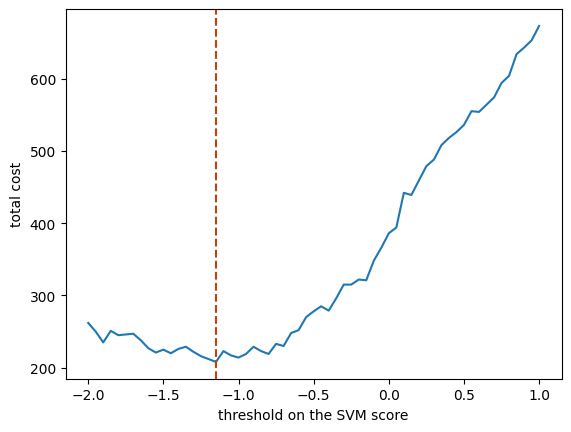

,TN,FP,FN,TP,precision,recall,cost
threshold -1.15,449,98,11,117,0.544,0.914,208
threshold 0,531,16,37,91,0.850,0.711,386


In [10]:
dev_scores = cross_val_predict(best_svm, X_dev, y_dev, cv=CV, method="decision_function")
thresholds = np.round(np.arange(-2, 1.0001, 0.05), 2)
costs = [evaluate(y_dev, (dev_scores >= t).astype(int))["cost"] for t in thresholds]
best_threshold = thresholds[int(np.argmin(costs))]
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="#C2410C", ls="--")
plt.xlabel("threshold on the SVM score"); plt.ylabel("total cost"); plt.show()
display(pd.DataFrame([evaluate(y_dev, (dev_scores >= best_threshold).astype(int)), evaluate(y_dev, (dev_scores >= 0).astype(int))],
                     index=[f"threshold {best_threshold}", "threshold 0"]).round(3))

**Solution notes (step 6).** The lowest development cost is **208 at the threshold −1.15** (TN 449, FP 98, FN 11, TP 117; recall 0.91),
compared with 386 at the threshold 0 (FN 37, FP 16; recall 0.71) and 1280 for “everything normal”. The cost curve is flat near the minimum,
so neighbouring thresholds give similar costs. Choosing the threshold on the test set would make the test result optimistic: the test
would no longer be an independent check.

## 7. Final test (once)

**Goal / output:** `test_scores` = `best_svm.decision_function(X_test)`, the ROC AUC on the test set and a table `test_result` with
`evaluate` at `best_threshold` and at 0, and the cost of “everything normal” on the test set. Nothing is tuned any more.

**Your code:**

In [11]:
test_scores = best_svm.decision_function(X_test)
print("test ROC AUC:", round(roc_auc_score(y_test, test_scores), 3))
test_result = pd.DataFrame([evaluate(y_test, (test_scores >= best_threshold).astype(int)), evaluate(y_test, (test_scores >= 0).astype(int))],
                           index=[f"threshold {best_threshold}", "threshold 0"])
display(test_result.round(3))
print("cost of 'everything normal':", 10 * int(y_test.sum()))

test ROC AUC: 0.952


,TN,FP,FN,TP,precision,recall,cost
threshold -1.15,156,26,5,38,0.594,0.884,76
threshold 0,178,4,16,27,0.871,0.628,164


cost of 'everything normal': 430


**Solution notes (step 7).** Test ROC AUC 0.952, close to the cross-validated 0.950. At the threshold −1.15 the cost is **76**
(FN 5, FP 26, recall 0.88), at the threshold 0 it is 164 (FN 16, FP 4) and “everything normal” costs 430.

## 8. One-class SVM without labelled faults (extension)

Steps 8 and 9 are an extension: do them in class if time allows, otherwise at home.

In practice, labelled faults are often missing; only records of normal operation exist. **Goal / output:** a table `oc_results`
with the validation ROC AUC of a one-class SVM for ν ∈ {0.02, 0.05, 0.1} and γ ∈ {0.03, 0.1, 0.3, 1}, the chosen settings,
and the test ROC AUC of the final one-class model `oc_model`.

1. Split the development data once more: `X_oc_train, X_oc_val, y_oc_train, y_oc_val` (30 % validation, stratified, `SEED`).
2. For each combination fit `Pipeline([("scale", StandardScaler()), ("model", OneClassSVM(nu=..., gamma=...))])`
   **only on the normal records** `X_oc_train[y_oc_train == 0]`; evaluate the ROC AUC on `X_oc_val` with the score
   `-model.decision_function(...)` (higher = more anomalous).
3. Refit the best combination on all normal development records; report the test ROC AUC, the share of normal test records flagged
   and the share of test faults found (`predict == -1`).

**Use:** `train_test_split`, `OneClassSVM`, `roc_auc_score`, `.decision_function`, `.predict`.

<details><summary>Hint</summary>

The labels of the validation part are used only to **evaluate** the settings, never to fit the model. `decision_function` of a one-class
SVM is positive inside the boundary, so its negative value is the anomaly score.

</details>

**Think about:** How far is the one-class model from the supervised SVM of step 7? When would you still prefer it?

**Your code:**

In [12]:
X_oc_train, X_oc_val, y_oc_train, y_oc_val = train_test_split(X_dev, y_dev, test_size=0.3, stratify=y_dev, random_state=SEED)
rows = []
for nu in (0.02, 0.05, 0.1):
    for gamma in (0.03, 0.1, 0.3, 1):
        model = Pipeline([("scale", StandardScaler()), ("model", OneClassSVM(nu=nu, gamma=gamma))]).fit(X_oc_train[y_oc_train == 0])
        rows.append({"nu": nu, "gamma": gamma, "validation ROC AUC": roc_auc_score(y_oc_val, -model.decision_function(X_oc_val))})
oc_results = pd.DataFrame(rows)
display(oc_results.pivot_table(index="nu", columns="gamma", values="validation ROC AUC").round(3))
best = oc_results.iloc[oc_results.iloc[:, 2].idxmax()]
oc_model = Pipeline([("scale", StandardScaler()), ("model", OneClassSVM(nu=best["nu"], gamma=best["gamma"]))]).fit(X_dev[y_dev == 0])
print("chosen ν =", best["nu"], "γ =", best["gamma"])
print("test ROC AUC:", round(roc_auc_score(y_test, -oc_model.decision_function(X_test)), 3))
print("normal records flagged:", round((oc_model.predict(X_test[y_test == 0]) == -1).mean(), 3),
      "| faults found:", round((oc_model.predict(X_test[y_test == 1]) == -1).mean(), 3))

gamma,0.03,0.10,0.30,1.00
nu,,,,
0.02,0.719,0.766,0.821,0.800
0.05,0.718,0.759,0.821,0.801
0.10,0.714,0.763,0.823,0.801


chosen ν = 0.1 γ = 0.3
test ROC AUC: 0.854
normal records flagged: 0.137 | faults found: 0.721


**Solution notes (step 8).** The validation ROC AUC is 0.71–0.82; γ matters much more than ν. The best is ν = 0.1, γ = 0.3 (0.823).
On the test set the one-class model reaches ROC AUC **0.854** without a single labelled fault, compared with 0.952 for the supervised SVM.
It flags 14 % of the normal test records and finds 72 % of the faults. It is the choice when faults are missing in the data
or are new and different from the known ones; the supervised model is better when enough labelled faults exist.

## 9. Pump curve: regression with the ε-tube and extrapolation (extension)

**Goal / output:** a table `svr_results` with the MAE of three SVR models inside and outside the training range, a plot of the three
curves, and a table `eps_results` with the number of support vectors and the MAE for ε ∈ {0.05, 0.2, 0.5}.

1. Take the **normal** development records (`y_dev == 0`). Inputs: `flow` only, target: `pressure`.
   Training range: flow < 65 m³/h; “new range”: flow ≥ 65 (the pump has never run there in the training data).
2. Fit three pipelines (scaling → `SVR`) with `C=10, epsilon=0.2`: linear kernel, polynomial `degree=2, coef0=1`, RBF `gamma=1`.
   Report the MAE in the training range and in the new range.
3. Plot the data and the three curves for flow from 20 to 80.
4. With the polynomial kernel change ε to 0.05, 0.2 and 0.5; report the number of support vectors and both MAE values.

**Use:** `SVR`, `mean_absolute_error`, `.support_`, `plt.plot`.

<details><summary>Hint</summary>

`SVR` needs a two-dimensional input: `data[["flow"]]`, not `data["flow"]`. The noise of the pressure around the curve has a standard
deviation of about 0.45 bar, so an MAE of about 0.27 is the best that any model can reach inside the data.

</details>

**Think about:** Which kernel extrapolates best and why (lecture slide on extrapolation)? Why does ε barely change the MAE
but strongly change the number of support vectors?

**Your code:**

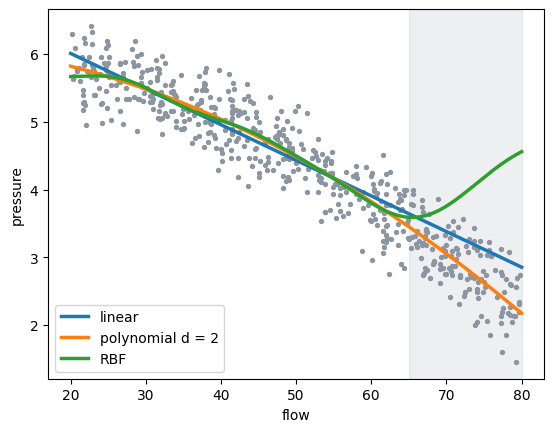

,MAE known range,MAE new range
linear,0.278,0.448
polynomial d = 2,0.271,0.297
RBF,0.270,1.120


,support vectors,MAE known range,MAE new range
0.05,370.0,0.271,0.298
0.20,230.0,0.271,0.297
0.50,56.0,0.272,0.310


In [13]:
normal = raw.loc[X_dev.index][y_dev == 0]
known = normal["flow"] < 65
X_known, y_known = normal.loc[known, ["flow"]], normal.loc[known, "pressure"]
X_new, y_new = normal.loc[~known, ["flow"]], normal.loc[~known, "pressure"]
regressors = {"linear": SVR(kernel="linear", C=10, epsilon=0.2),
              "polynomial d = 2": SVR(kernel="poly", degree=2, coef0=1, C=10, epsilon=0.2),
              "RBF": SVR(kernel="rbf", gamma=1, C=10, epsilon=0.2)}
grid_flow = pd.DataFrame({"flow": np.linspace(20, 80, 200)})
rows = {}
plt.scatter(normal["flow"], normal["pressure"], s=8, color="#8C96A0")
plt.axvspan(65, 80, color="#8C96A0", alpha=0.15)
for name, reg in regressors.items():
    model = Pipeline([("scale", StandardScaler()), ("model", reg)]).fit(X_known, y_known)
    rows[name] = {"MAE known range": mean_absolute_error(y_known, model.predict(X_known)),
                  "MAE new range": mean_absolute_error(y_new, model.predict(X_new))}
    plt.plot(grid_flow["flow"], model.predict(grid_flow), lw=2.5, label=name)
plt.xlabel("flow"); plt.ylabel("pressure"); plt.legend(); plt.show()
svr_results = pd.DataFrame(rows).T
display(svr_results.round(3))

rows = {}
for eps in (0.05, 0.2, 0.5):
    model = Pipeline([("scale", StandardScaler()), ("model", SVR(kernel="poly", degree=2, coef0=1, C=10, epsilon=eps))]).fit(X_known, y_known)
    rows[eps] = {"support vectors": len(model[-1].support_), "MAE known range": mean_absolute_error(y_known, model.predict(X_known)),
                 "MAE new range": mean_absolute_error(y_new, model.predict(X_new))}
eps_results = pd.DataFrame(rows).T
display(eps_results.round(3))

**Solution notes (step 9).** 410 normal records lie in the training range and 137 in the new range. In the training range all three
models have an MAE of about 0.27–0.28 bar. In the new range the polynomial kernel keeps **0.30**, the linear one rises to 0.45
(the curve is a parabola, not a line) and the RBF kernel to **1.12**: outside the data its prediction returns towards a constant,
exactly as on the lecture slide. ε = 0.05, 0.2 and 0.5 give 370, 230 and 56 support vectors with almost the same MAE (0.30–0.31 in the new range):
only points outside the tube carry the solution, and the noise of 0.45 bar is much larger than any of the tubes.

## Summary

* A class that surrounds the other one (deviation on either side) needs a kernel; a linear model is no better than chance.
* C and γ are tuned together; a best value on the edge of the grid means extending the grid.
* The threshold on the SVM score is chosen by the cost of errors on the development data, then the test is opened once.
* The one-class SVM works without labelled faults, at the price of a weaker result.
* The RBF kernel does not extrapolate; a model with the right shape (here a parabola) does.